<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">


# Procesamiento de lenguaje natural
# **Ejercicio, Traductor**

Importamos las librerias necesarias

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping
from tensorflow.keras.layers import Input, LSTM, Dense, Embedding, Dropout
from tensorflow.keras.models import Model
import pickle
import os

Descargamos el dataset de traducción de Español-Inglés

In [ ]:
if not os.path.exists('spa-eng'):
    os.system("curl -L -o spa-eng.zip http://storage.googleapis.com/download.tensorflow.org/data/spa-eng.zip")
    os.system("unzip -q spa-eng.zip")

with open("./spa-eng/spa.txt") as f:
    lines = f.read().split("\n")[:-1]

Definimos el número máximo de oraciones y la semilla

In [ ]:
MAX_NUM_SENTENCES = 10000

np.random.seed(40)
# Semilla también para TensorFlow (resultados más reproducibles)
tf.random.set_seed(40)
np.random.shuffle(lines)

Cargamos los datos

In [ ]:
input_sentences, output_sentences, output_sentences_inputs = [], [], []

for i, line in enumerate(lines):
    if i >= MAX_NUM_SENTENCES:
        break
    if '\t' not in line:
        continue
    input_sentence, output = line.rstrip().split('\t')[:2]
    output_sentences.append(output + ' <eos>')
    output_sentences_inputs.append('<sos> ' + output)
    input_sentences.append(input_sentence)

print(f"Oraciones cargadas: {len(input_sentences)}")

Oraciones cargadas: 10000


In [ ]:
print(input_sentences[0])
print(output_sentences[0])
print(output_sentences_inputs[0])

Somebody stole my car.
Alguien robó mi auto. <eos>
<sos> Alguien robó mi auto.


Aplicamos tokenización

In [ ]:
MAX_VOCAB_SIZE = 8000

input_tokenizer = Tokenizer(num_words=MAX_VOCAB_SIZE)
input_tokenizer.fit_on_texts(input_sentences)
input_integer_seq = input_tokenizer.texts_to_sequences(input_sentences)
word2idx_inputs = input_tokenizer.word_index

#Solo se tomarán en cuenta las 8000 palabras más frecuentes y se eliminan signos de puntuación
# Se agrega '¡' al filtro (antes solo se filtraba '¿')
output_tokenizer = Tokenizer(
    num_words=MAX_VOCAB_SIZE,
    filters='!"#$%&()*+,-./:;=¿¡?@[\\]^_`{|}~\t\n'
)

output_tokenizer.fit_on_texts(["<sos>", "<eos>"] + output_sentences)
output_integer_seq = output_tokenizer.texts_to_sequences(output_sentences)
output_input_integer_seq = output_tokenizer.texts_to_sequences(output_sentences_inputs)
word2idx_outputs = output_tokenizer.word_index

num_words_output = min(len(word2idx_outputs) + 1, MAX_VOCAB_SIZE)

# Largos máximos calculados a partir de los datos (antes estaban fijos a mano)
max_input_len = max(len(s) for s in input_integer_seq)
max_out_len   = max(len(s) for s in output_integer_seq)

print(f"Vocabulario EN: {len(word2idx_inputs)} | ES: {len(word2idx_outputs)}")
print(f"max_input_len={max_input_len}  max_out_len={max_out_len}")

Vocabulario EN: 4977 | ES: 7757
max_input_len=26  max_out_len=32


Aplicamos padding a las secuencias

In [ ]:
encoder_input_sequences  = pad_sequences(input_integer_seq,        maxlen=max_input_len)
# truncating='post' para no perder <sos> si una oración fuera demasiado larga
decoder_input_sequences  = pad_sequences(output_input_integer_seq, maxlen=max_out_len, padding='post', truncating='post')
decoder_output_sequences = pad_sequences(output_integer_seq,       maxlen=max_out_len, padding='post', truncating='post')

In [ ]:
print(encoder_input_sequences[0])
print(decoder_input_sequences[0])
print(decoder_output_sequences[0])

[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0 702 752  16 104]
[3431  157  612   21  247    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0]
[157 612  21 247   1   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0]


Definimos función para obtener un tf.data.Dataset.

Esta función construye un tf.data.Dataset que genera batches de ((encoder_in, decoder_in), target, peso). Los targets son índices enteros (sin one-hot) y el peso vale 0 en las posiciones de padding, para que no cuenten en la loss ni en el accuracy.

In [ ]:
# Dataset directo desde arrays (reemplaza al generador) con targets enteros
def make_dataset(enc_seqs, dec_in_seqs, dec_out_seqs, batch_size, shuffle=False):

    # Peso 0 en el padding: así no cuenta en la loss ni en el accuracy
    sample_weights = (dec_out_seqs != 0).astype(np.float32)

    ds = tf.data.Dataset.from_tensor_slices((
        (enc_seqs.astype(np.int32), dec_in_seqs.astype(np.int32)),
        dec_out_seqs.astype(np.int32),
        sample_weights,
    ))
    # Mezclamos el set de entrenamiento en cada época
    if shuffle:
        ds = ds.shuffle(len(enc_seqs), seed=40, reshuffle_each_iteration=True)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

Aplicamos la función en el dataset para obtener el train y validation set

In [ ]:
BATCH_SIZE = 64
val_split  = 0.15
split_idx  = int(len(encoder_input_sequences) * (1 - val_split))

train_ds = make_dataset(
    encoder_input_sequences[:split_idx],
    decoder_input_sequences[:split_idx],
    decoder_output_sequences[:split_idx],
    BATCH_SIZE, shuffle=True
)
val_ds = make_dataset(
    encoder_input_sequences[split_idx:],
    decoder_input_sequences[split_idx:],
    decoder_output_sequences[split_idx:],
    BATCH_SIZE
)

Definimos función para descargar los embeddings de GloVe

In [ ]:
def _is_valid_pickle(path):
    try:
        with open(path, 'rb') as f:
            head = f.read(20)
        return b'<html' not in head.lower() and b'<!doctype' not in head.lower()
    except Exception:
        return False

_PKL_PATH = 'gloveembedding.pkl'
_FILE_ID  = '1KY6avD5I1eI2dxQzMkR3WExwKwRq2g94'

if not os.path.exists(_PKL_PATH) or not _is_valid_pickle(_PKL_PATH):
    print("Descargando gloveembedding.pkl desde Google Drive...")
    if os.path.exists(_PKL_PATH):
        os.remove(_PKL_PATH)
    try:
        import gdown
        gdown.download(id=_FILE_ID, output=_PKL_PATH, quiet=False)
    except Exception:
        os.system(f"curl -L -o {_PKL_PATH} "
                  f"'https://drive.google.com/u/0/uc?id={_FILE_ID}&export=download&confirm=t'")
    if not _is_valid_pickle(_PKL_PATH):
        raise ValueError("El archivo descargado no es un pickle válido.")
    print("Descarga completada.")
else:
    print("gloveembedding.pkl ya disponible.")

gloveembedding.pkl ya disponible.


Definimos función para cargar los embeddings de GloVe

In [ ]:
def load_glove_embeddings(pkl_path):
    """Carga el pickle de GloVe y devuelve (word2idx, matrix_fn)."""
    max_bytes = 2**28 - 1
    raw = bytearray()
    sz  = os.path.getsize(pkl_path)
    with open(pkl_path, 'rb') as f:
        for _ in range(0, sz, max_bytes):
            raw += f.read(max_bytes)
    embeddings = pickle.loads(raw)
    idx_array  = np.arange(embeddings.shape[0])
    word2idx   = dict(zip(embeddings['word'], idx_array))
    return embeddings, word2idx

Definimos función para obtener el embedding por palabra

In [ ]:
def get_word_embedding(word, embeddings, word2idx, n_features=50):
    i = word2idx.get(word, -1)
    return embeddings[i]['embedding'] if i != -1 else np.zeros(n_features)

Definimos función para armar la matriz de embeddings

In [ ]:
def build_embedding_matrix(word2idx_inputs, embeddings, word2idx_glove,
                            nb_words, embed_dim=50):
    matrix = np.zeros((nb_words, embed_dim))
    for word, i in word2idx_inputs.items():
        if i < nb_words:
            vec = get_word_embedding(word, embeddings, word2idx_glove, embed_dim)
            if vec is not None and len(vec) > 0:
                matrix[i] = vec
    return matrix

In [ ]:
EMBED_DIM = 50
# +1 porque los índices del tokenizer empiezan en 1 (el 0 es padding)
nb_words  = min(MAX_VOCAB_SIZE, len(word2idx_inputs) + 1)

glove_embeddings, glove_word2idx = load_glove_embeddings(_PKL_PATH)
embedding_matrix = build_embedding_matrix(
    word2idx_inputs, glove_embeddings, glove_word2idx, nb_words, EMBED_DIM
)
# Se excluye la fila 0 (padding) del conteo
print(f"Embeddings nulos: {np.sum(np.sum(embedding_matrix[1:]**2, axis=1) == 0)}")

Embeddings nulos: 211


### **Modelo Seq2Seq**

In [ ]:
n_units = 256

Definimos función para armar el encoder. Esta función devuelve (encoder_inputs, encoder_states, encoder_emb_layer, encoder_lstm_layer) para poder reusar las capas en el modelo de inferencia.

In [ ]:
def build_encoder(nb_words, embed_dim, embedding_matrix, max_input_len, n_units):

    enc_inputs   = Input(shape=(max_input_len,), name='encoder_inputs')

    # Se quita input_length (deprecado)
    enc_emb_layer = Embedding(
        input_dim=nb_words,
        output_dim=embed_dim,
        weights=[embedding_matrix],
        trainable=False,
        name='encoder_embedding'
    )
    enc_emb = Dropout(0.3, name='encoder_dropout')(enc_emb_layer(enc_inputs))

    enc_lstm_layer = LSTM(n_units, return_state=True, name='encoder_lstm')
    _, state_h, state_c = enc_lstm_layer(enc_emb)

    return enc_inputs, [state_h, state_c], enc_emb_layer, enc_lstm_layer

Definimos función para armar el decoder. Esta función devuelve (decoder_inputs, decoder_outputs, dec_emb_layer, dec_lstm_layer, dec_dense_layer)
    para reusar las capas en inferencia.

In [ ]:
def build_decoder(num_words_output, max_out_len, n_units, encoder_states):

    dec_inputs = Input(shape=(max_out_len,), name='decoder_inputs')

    # Se quita input_length (deprecado)
    dec_emb_layer = Embedding(
        input_dim=num_words_output,
        output_dim=n_units,
        name='decoder_embedding'
    )
    dec_emb = Dropout(0.3, name='decoder_dropout')(dec_emb_layer(dec_inputs))

    dec_lstm_layer = LSTM(n_units, return_sequences=True, return_state=True,
                          name='decoder_lstm')
    dec_out, _, _  = dec_lstm_layer(dec_emb, initial_state=encoder_states)

    dec_dense_layer = Dense(num_words_output, activation='softmax', name='decoder_dense')
    dec_out         = dec_dense_layer(dec_out)

    return dec_inputs, dec_out, dec_emb_layer, dec_lstm_layer, dec_dense_layer

Construimos encoder y decoder

In [ ]:
enc_inputs, enc_states, enc_emb_layer, enc_lstm_layer = build_encoder(
    nb_words, EMBED_DIM, embedding_matrix, max_input_len, n_units
)
dec_inputs, dec_outputs, dec_emb_layer, dec_lstm_layer, dec_dense_layer = build_decoder(
    num_words_output, max_out_len, n_units, enc_states
)

In [ ]:
model = Model([enc_inputs, dec_inputs], dec_outputs)

Definimos callbacks

In [ ]:
lr_scheduler = ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=4, min_lr=1e-5, verbose=1
)
early_stop = EarlyStopping(
    monitor='val_loss', patience=6, restore_best_weights=True, verbose=1
)

Compilamos el modelo. Usamos `sparse_categorical_crossentropy` (targets enteros) y `weighted_metrics` para que el accuracy ignore el padding y mida solo palabras reales.

In [ ]:
# Loss sparse (sin one-hot) y accuracy ponderado que ignora el padding
model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-4),
    weighted_metrics=['accuracy']
)

Entrenamos el modelo

In [ ]:
# Más épocas: el EarlyStopping corta cuando la val_loss deja de mejorar
hist = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=100,
    callbacks=[lr_scheduler, early_stop]
)

Epoch 1/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 15s 53ms/step - accuracy: 0.1464 - loss: 1.4604 - val_accuracy: 0.1553 - val_loss: 1.3552 - learning_rate: 5.0000e-04
Epoch 2/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 7s 52ms/step - accuracy: 0.1614 - loss: 1.2960 - val_accuracy: 0.1644 - val_loss: 1.3101 - learning_rate: 5.0000e-04
Epoch 3/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 10s 54ms/step - accuracy: 0.1703 - loss: 1.2497 - val_accuracy: 0.1766 - val_loss: 1.2848 - learning_rate: 5.0000e-04
Epoch 4/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 7s 50ms/step - accuracy: 0.1840 - loss: 1.2107 - val_accuracy: 0.1889 - val_loss: 1.2627 - learning_rate: 5.0000e-04
Epoch 5/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 7s 52ms/step - accuracy: 0.1985 - loss: 1.1743 - val_accuracy: 0.2034 - val_loss: 1.2395 - learning_rate: 5.0000e-04
Epoch 6/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 10s 53ms/step - accuracy: 0.2127 - loss: 1.1405 - val_accuracy: 0.2136 - val_loss: 1.2172 - learning_rate: 5.0000e-04
Epoch 7/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 7s 50ms/

Visualizamos el accuracy durante el entrenamiento

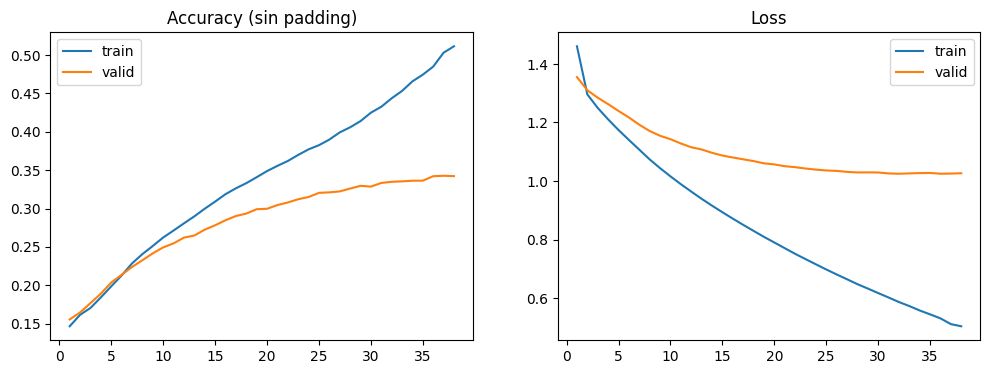

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

epoch_count = range(1, len(hist.history['loss']) + 1)

# Graficamos accuracy y loss lado a lado
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.lineplot(x=epoch_count, y=hist.history['accuracy'],     label='train', ax=axes[0])
sns.lineplot(x=epoch_count, y=hist.history['val_accuracy'], label='valid', ax=axes[0])
axes[0].set_title("Accuracy (sin padding)")
sns.lineplot(x=epoch_count, y=hist.history['loss'],     label='train', ax=axes[1])
sns.lineplot(x=epoch_count, y=hist.history['val_loss'], label='valid', ax=axes[1])
axes[1].set_title("Loss")
plt.show()

### **Inferencia Modelo Seq2Seq**

Definimos el modelo Seq2Seq para realizar inferencia

In [ ]:
def build_encoder_inference(enc_inputs, enc_emb_layer, enc_lstm_layer, n_units):
    """Modelo de encoder que solo devuelve los estados."""
    enc_emb = enc_emb_layer(enc_inputs)                    # reutiliza pesos entrenados
    _, state_h, state_c = enc_lstm_layer(enc_emb)
    return Model(enc_inputs, [state_h, state_c])


def build_decoder_inference(dec_emb_layer, dec_lstm_layer, dec_dense_layer, n_units):
    """Modelo de decoder paso a paso (un token por vez)."""
    dec_input_single = Input(shape=(1,), name='dec_input_single')
    dec_state_h_in   = Input(shape=(n_units,), name='dec_state_h')
    dec_state_c_in   = Input(shape=(n_units,), name='dec_state_c')

    dec_emb_single = dec_emb_layer(dec_input_single)      # reutiliza pesos entrenados
    dec_out, h_out, c_out = dec_lstm_layer(
        dec_emb_single,
        initial_state=[dec_state_h_in, dec_state_c_in]
    )
    dec_out = dec_dense_layer(dec_out)

    return Model(
        [dec_input_single, dec_state_h_in, dec_state_c_in],
        [dec_out, h_out, c_out]
    )

In [ ]:
encoder_model = build_encoder_inference(enc_inputs, enc_emb_layer, enc_lstm_layer, n_units)
decoder_model = build_decoder_inference(dec_emb_layer, dec_lstm_layer, dec_dense_layer, n_units)

Aplicamos inferencia greedy

In [ ]:
idx2word_input  = {v: k for k, v in word2idx_inputs.items()}
idx2word_target = {v: k for k, v in word2idx_outputs.items()}

Definimos funciones para realizar traducciones

In [ ]:
def translate_sentence(input_seq):
    # Llamamos a los modelos directamente (más rápido que .predict token a token)
    h, c = encoder_model(input_seq, training=False)
    target_seq      = np.zeros((1, 1))
    target_seq[0, 0] = word2idx_outputs['<sos>']
    eos = word2idx_outputs['<eos>']

    output_sentence = []
    for _ in range(max_out_len):
        output_tokens, h, c = decoder_model([tf.constant(target_seq), h, c], training=False)
        idx = int(np.argmax(output_tokens[0, 0, :]))
        if idx == eos:
            break
        if idx > 0:
            output_sentence.append(idx2word_target[idx])
        target_seq[0, 0] = idx

    return ' '.join(output_sentence)


def translate(text):
    seq = input_tokenizer.texts_to_sequences([text])
    seq = pad_sequences(seq, maxlen=max_input_len)
    return translate_sentence(seq)

Realizamos pruebas

In [ ]:
# Ejemplos tomados del set de validación (oraciones que el modelo no vio)
print("\n--- Ejemplos de validación ---")
for _ in range(5):
    i    = np.random.randint(split_idx, len(input_sentences))
    seq  = encoder_input_sequences[i:i+1]
    pred = translate_sentence(seq)
    print(f"EN: {input_sentences[i]}")
    print(f"ES (real): {output_sentences[i].replace(' <eos>', '')}")
    print(f"ES (pred): {pred}\n")

print("--- Frases nuevas ---")
for s in ["My mother says hi.", "Where is the train station?",
          "I love learning languages.", "Can you help me?"]:
    print(f"EN: {s}")
    print(f"ES: {translate(s)}\n")


--- Ejemplos de validación ---
EN: People make mistakes in a situation like this.
ES (real): En una situación así se cometen errores.
ES (pred): cuántos personas no hay nada de la vida

EN: Do whatever he tells you.
ES (real): Haz lo que te diga.
ES (pred): lo que me dijo

EN: Don't you have anything better to do?
ES (real): ¿No tiene nada mejor que hacer?
ES (pred): tienes que hacer eso

EN: My brother became a cook.
ES (real): Mi hermano se ha vuelto un gallito.
ES (pred): mi hermano me dio un poco

EN: Tom doesn't do drugs.
ES (real): Tom no consume drogas.
ES (pred): tom no tiene nada

--- Frases nuevas ---
EN: My mother says hi.
ES: mi padre me dijo

EN: Where is the train station?
ES: dónde está en la habitación

EN: I love learning languages.
ES: me gusta el café

EN: Can you help me?
ES: puedes hablar conmigo

